# CT simulation of a $ CO_2 $ hydrate sample

Work plan until the next meeting:

1. Attenuation of $ CO_2 $ hydrate, water, ice and sandstone
2. A hydrate-bearing sandstone sample
3. X-ray tube spectrum: which energies make hydrate easiest to see
4. Phase transitions
5. Induction time (latenstid)

Units: lengths in mm, $\mu$ in 1/mm, energies in keV, pressure in MPa, temperature in K unless stated.

In [102]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from scipy import ndimage as ndi
import scipy.stats as spst
from skimage.transform import radon, iradon
import xraylib as xrl
import porespy as ps 

## 1. Attenuation coefficients

$\mu(E) = (\mu/\rho)(E)\cdot\rho$, with $\mu/\rho$ from xraylib (total cross section, including coherent scattering).

xraylib splits the chemical formula into elements and their mass fractions, looks up tabulated cross sections for each element and adds them up weighted by mass fraction (Schoonjans et al., 2011). The total includes photoelectric absorption, Compton scattering and Rayleigh scattering. In the CT range Compton scattering dominates for water, ice and hydrate (about 95 % of the total for water at 100 keV). Compton scattering depends mainly on the number of electrons per gram, which is why the three have almost the same $\mu/\rho$. Photoelectric absorption grows strongly with atomic number and dominates at low energy, which is why quartz attenuates much more than water there.

Hydrate attenuates about 6 % more than water because of two opposing effects. Per gram it attenuates about 3 % less than water ($\mu/\rho$ = 0.166 against 0.171 cm²/g at 100 keV), because part of its mass is CO₂ and it therefore contains less hydrogen (8 % against 11 % by mass). Hydrogen has the most electrons per gram and attenuates most per gram. Per volume, however, hydrate is 9 % denser than water (1.09 against 1.00 g/cm³). Together this gives $0.97 \times 1.09 \approx 1.06$.

* **CO₂ hydrate**: structure I, hydration number $n_h = 6.08$ and $\rho = 1.09$ g/cm³ (medical CT paper). The ideal values with all cages filled are $n_h = 5.75$ and $\rho \approx 1.10$ g/cm³.
* **Ice**: H₂O at 0.917 g/cm³.
* **Sandstone**: Bentheimer grains are mostly quartz with a few percent feldspar and clay. The composition is taken from the XRD measurements in Peksa et al. (2015), *Bentheimer sandstone revisited for experimental purposes*, Table 1: 91.7 wt% quartz, 4.9 wt% K-feldspar and 2.7 wt% clay (treated as kaolinite). The weight fractions are converted to volume fractions in the code.
* **CO₂**: gas at about 3 MPa and 1 °C has $\rho \approx 0.07$ g/cm³ (liquid CO₂ is about 0.9 g/cm³).

In [103]:
# name -> (chemical formula, density [g/cm^3])
MATERIALS = {
    "water":     ("H2O",           1.000),
    "ice":       ("H2O",           0.917),
    "hydrate":   ("CO2(H2O)6.08",  1.09),
    "CO2 gas":   ("CO2",           0.07),
    "quartz":    ("SiO2",          2.65),
    "feldspar":  ("KAlSi3O8",      2.56),
    "kaolinite": ("Al2Si2O5(OH)4", 2.60),
}

# Bentheimer grain composition, XRD weight fractions (Peksa et al. 2015, Table 1, "Bentheimer sandstone revisited for experimental purposes").
# Clay = kaolinite 2.50 + montmorillonite 0.18; the remaining 0.7 wt% (carbonates, oxides, pyrite) is left out.
SANDSTONE_WT = {"quartz": 0.9170, "feldspar": 0.0486, "kaolinite": 0.0268}
vol = {m: w / MATERIALS[m][1] for m, w in SANDSTONE_WT.items()}   # weight / density = volume
total = sum(vol.values())
SANDSTONE = {m: v / total for m, v in vol.items()}                # volume fractions, sum to 1


def density(name):
    # Density [g/cm^3]; for sandstone, volume-weighted average of the minerals
    if name == "sandstone":
        return sum(f * MATERIALS[m][1] for m, f in SANDSTONE.items())
    return MATERIALS[name][1]


def mu(name, energy):
    # Linear attenuation [1/mm] of a material at one or several energies [keV]
    if name == "sandstone":
        return sum(f * mu(m, energy) for m, f in SANDSTONE.items()) # volume-weighted average of the minerals in sandstone
    formula, rho = MATERIALS[name] # chemical formula, density [g/cm^3]
    E = np.atleast_1d(np.asarray(energy, float))
    out = np.array([xrl.CS_Total_CP(formula, float(e)) * rho / 10 for e in E]) # [cm^2/g] * [g/cm^3] -> [1/cm], then divide by 10 to get [1/mm]
    return out if np.ndim(energy) else out[0]


def mass_att(name, energy):
    # Mass attenuation coefficient mu/rho [cm^2/g]
    return mu(name, energy) * 10 / density(name)          # [1/mm] -> [1/cm], then divide by density

In [120]:
# breakdown of mu/rho [cm^2/g] at one energy: elements and interaction types
E_check = 100.0                                                         # [keV]
for name in ["water", "hydrate"]:
    formula = MATERIALS[name][0]
    comp = xrl.CompoundParser(formula)
    fractions = {xrl.AtomicNumberToSymbol(z): round(w, 3) for z, w in zip(comp["Elements"], comp["massFractions"])}
    print(f"{name}: mass fractions {fractions}")
    print(f"   photoelectric {xrl.CS_Photo_CP(formula, E_check):.4f}, Compton {xrl.CS_Compt_CP(formula, E_check):.4f}, "
          f"Rayleigh {xrl.CS_Rayl_CP(formula, E_check):.4f}, total {xrl.CS_Total_CP(formula, E_check):.4f} cm^2/g")

water: mass fractions {'H': 0.112, 'O': 0.888}
   photoelectric 0.0028, Compton 0.1626, Rayleigh 0.0053, total 0.1708 cm^2/g
hydrate: mass fractions {'H': 0.08, 'C': 0.078, 'O': 0.842}
   photoelectric 0.0027, Compton 0.1579, Rayleigh 0.0054, total 0.1660 cm^2/g


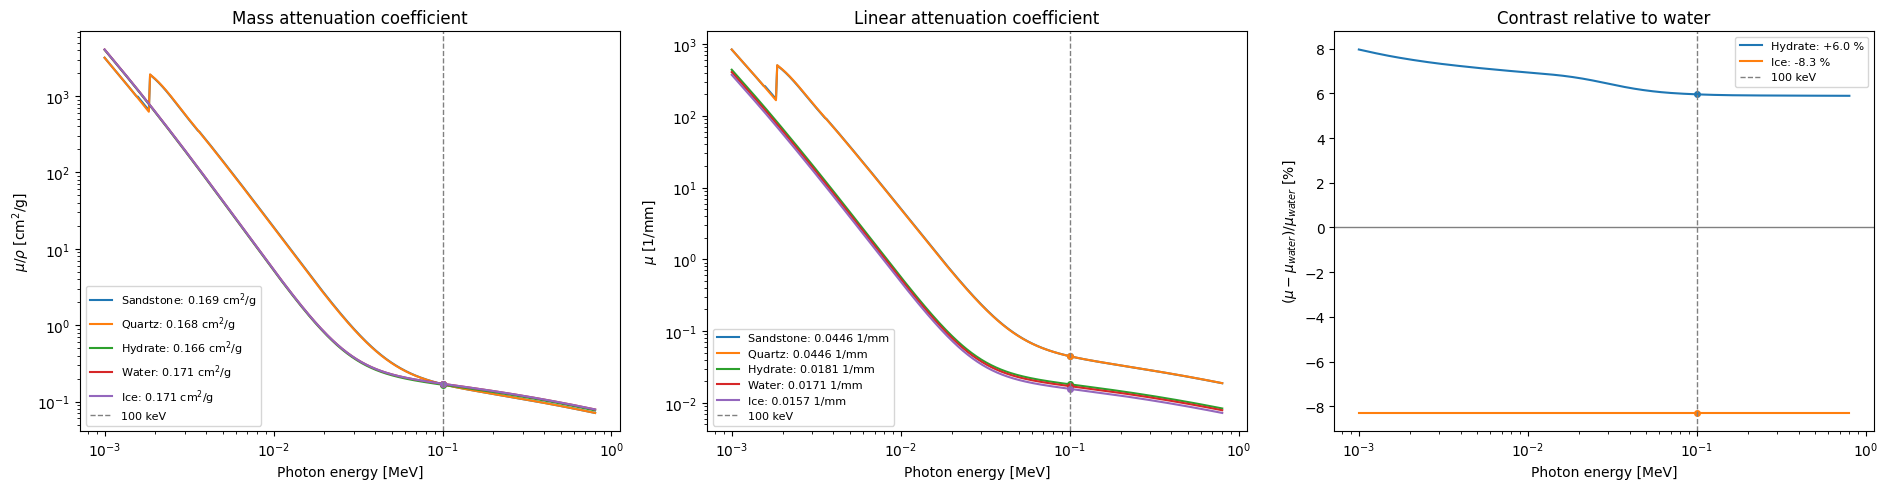

In [104]:
E = np.logspace(-3, np.log10(0.8), 400)            # MeV, 1 keV to 800 keV (xraylib stops below 1 MeV)
E_line = 0.1                                       # MeV
show = ["sandstone", "quartz", "hydrate", "water", "ice"]

fig, (ax0, ax1, ax2) = plt.subplots(1, 3, figsize=(19, 5))

# 1. mass attenuation: depends only on the chemistry, density divided out
for name in show:
    mu_rho = mass_att(name, E * 1e3)                       # functions take keV
    mu_rho_line = mass_att(name, E_line * 1e3)
    line, = ax0.loglog(E, mu_rho, label=f"{name.capitalize()}: {mu_rho_line:.3f} cm$^2$/g")
    ax0.plot(E_line, mu_rho_line, "o", ms=4, color=line.get_color())
ax0.set_ylabel(r"$\mu/\rho$ [cm$^2$/g]")
ax0.set_title("Mass attenuation coefficient")

# 2. linear attenuation: chemistry times density, this is what CT measures
for name in show:
    mu_E = mu(name, E * 1e3)
    mu_line = mu(name, E_line * 1e3)
    line, = ax1.loglog(E, mu_E, label=f"{name.capitalize()}: {mu_line:.4f} 1/mm")
    ax1.plot(E_line, mu_line, "o", ms=4, color=line.get_color())
ax1.set_ylabel(r"$\mu$ [1/mm]")
ax1.set_title("Linear attenuation coefficient")

# 3. relative to water: this is what decides whether two phases can be told apart
mu_w = mu("water", E * 1e3)
mu_w_line = mu("water", E_line * 1e3)
for name in ["hydrate", "ice"]:
    rel = 100 * (mu(name, E * 1e3) - mu_w) / mu_w
    rel_line = 100 * (mu(name, E_line * 1e3) - mu_w_line) / mu_w_line
    line, = ax2.semilogx(E, rel, label=f"{name.capitalize()}: {rel_line:+.1f} %")
    ax2.plot(E_line, rel_line, "o", ms=4, color=line.get_color())
ax2.axhline(0, color="grey", lw=1)
ax2.set_ylabel(r"$(\mu - \mu_{water})/\mu_{water}$ [%]")
ax2.set_title("Contrast relative to water")

for ax in (ax0, ax1, ax2):
    ax.axvline(E_line, color="grey", ls="--", lw=1, label=f"{E_line * 1e3:.0f} keV")
    ax.set_xlabel("Photon energy [MeV]")
    ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

In [105]:
# table at a few energies
energies_table = [40, 60, 80, 100, 140]
names = ["water", "ice", "hydrate", "CO2 gas", "quartz", "sandstone"]

print("Linear attenuation coefficient mu [1/mm]")
print(f"{'material':10s}" + "".join(f"{e:>10d} keV" for e in energies_table))
for name in names:
    print(f"{name:10s}" + "".join(f"{mu(name, e):14.5f}" for e in energies_table))
print()
print("Contrast relative to water, (mu - mu_water) / mu_water [%]")
for name in ["hydrate", "ice"]:
    rel = [100 * (mu(name, e) - mu("water", e)) / mu("water", e) for e in energies_table]
    print(f"{name:14s}" + "".join(f"{r:+14.1f}" for r in rel))

print()
print("Contrast relative to ice, (mu_hydrate - mu_ice) / mu_ice [%]")
rel = [100 * (mu("hydrate", e) - mu("ice", e)) / mu("ice", e) for e in energies_table]
print(f"{'hydrate':14s}" + "".join(f"{r:+14.1f}" for r in rel))

Linear attenuation coefficient mu [1/mm]
material          40 keV        60 keV        80 keV       100 keV       140 keV
water            0.02683       0.02059       0.01837       0.01708       0.01539
ice              0.02460       0.01888       0.01684       0.01566       0.01411
hydrate          0.02850       0.02184       0.01947       0.01809       0.01630
CO2 gas          0.00171       0.00131       0.00116       0.00108       0.00097
quartz           0.12331       0.06664       0.05129       0.04463       0.03820
sandstone        0.12450       0.06692       0.05135       0.04462       0.03814

Contrast relative to water, (mu - mu_water) / mu_water [%]
hydrate                 +6.2          +6.1          +6.0          +6.0          +5.9
ice                     -8.3          -8.3          -8.3          -8.3          -8.3

Contrast relative to ice, (mu_hydrate - mu_ice) / mu_ice [%]
hydrate                +15.9         +15.7         +15.6         +15.5         +15.5


**Takeaways**

* Water, ice and hydrate have almost the same mass attenuation coefficient, since they are mostly H₂O. The contrast between them in CT comes mainly from the difference in density.
* Hydrate attenuates about 6 % more than water (5.9–6.2 % between 40 and 140 keV). Ice attenuates exactly 8.3 % less than water at all energies, since it is the same molecule at 0.917 times the density.
* Hydrate and ice therefore differ by about 15–16 %, which is much easier to see than hydrate versus water.
* The relative contrast is almost independent of energy in the CT range, so changing the energy alone will not make hydrate easier to see. Noise and beam hardening decide the best energy (section 3).
* CO₂ gas attenuates about 94 % less than water and is easy to separate from all the other phases.
* Sandstone grains attenuate 2.5–4.6 times more than water (from 140 to 40 keV), so the grains set the grey-scale range and hide the small differences in the pores unless the window is narrowed.

## 2. Hydrate sample

The sample is built in the order things happen in the experiment:

1. **Sandstone.** Random overlapping grains (PoreSpy, `polydisperse_spheres`) with radii 0.7–1.3 times the mean grain radius, until the porosity of the core is 23 %. The pores are 100 % water.
2. **CO₂ injection.** In a water-wet rock CO₂ displaces water from the widest pores first (capillary drainage). The pore size of each pixel is calculated as the local thickness (PoreSpy), the radius of the largest disk that fits in the pore space and covers the pixel. Water stays in throats, contacts and corners.
3. **Hydrate growth.** Hydrate nucleates at a few random points on the water–CO₂ interface, spreads quickly along the interface as a film, then thickens slowly. Hydrate takes up more volume than the water it consumed. The expansion factor, about 1.29, is calculated from the hydration number and hydrate density ($n_h = 6.08$, $\rho_H = 1.09$ g/cm³), the same way as in the equation for $S_H$. The extra volume grows into the CO₂.

The rock (steps 1 and 2) is made by `make_rock`, and the fluids (steps 2 and 3) by `fill_pores`. The same rock can therefore be reused for different saturations, for example for a reference sample without hydrate.

The grains are given the averaged sandstone attenuation from section 1.

**Assumptions to state in the report:**
* 2D slice.
* CO₂ placement by pore size only, without connectivity. This is reasonable for a slice across the flow direction, since pores connect through the third dimension.
* Hydrate nucleates only on the water–CO₂ interface, not on grain surfaces or clays.
* The model gives mainly pore-filling and patchy hydrate, not grain-coating or cementing.
* No thin water films between hydrate and grains.
* Pure water without salt, as in the experiments.
* One average grain material.

porosity: 0.230
saturations: {'water': np.float64(0.3), 'hydrate': np.float64(0.6), 'CO2': np.float64(0.1)}


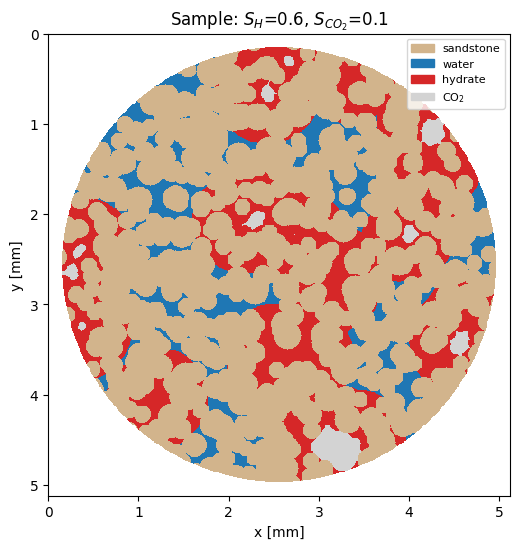

In [117]:
# ---- inputs
S_H = 0.6                   # hydrate saturation (fraction of pore volume)
S_CO2 = 0.1                 # free CO2 saturation (fraction of pore volume); water fills the rest
# example: 40 % water at the start, 90 % of it converted -> S_H = EXPANSION * 0.9 * 0.4 = 0.46, S_w = 0.04

n_pixel, pixel_size = 512, 0.01                         # 10 um pixels -> 5.12 mm image
core_radius, grain_radius = 2.4, 0.12                   # [mm]
porosity = 0.23                                         # pore volume / core volume

GRAIN, WATER, HYDRATE, CO2 = 1, 2, 3, 4
LABEL_MATERIAL = {GRAIN: "sandstone", WATER: "water", HYDRATE: "hydrate", CO2: "CO2 gas"}

n_h, rho_H = 6.08, 1.09                                 # hydration number, hydrate density [g/cm^3]
M_H2O, M_CO2 = 18.015, 44.01                            # molar masses [g/mol]
EXPANSION = ((M_H2O + M_CO2 / n_h) / rho_H) / M_H2O     # hydrate volume / water volume (same as eq. for S_H), ~1.29
N_NUCLEI = 50               # nucleation sites on the water-CO2 interface
LATERAL = 5                 # film spreads this many times faster along the interface than it thickens


def make_rock(seed=0):
    """
    Grains and pore space, independent of the saturations.
    Returns grain, pore (boolean images) and idx: pore pixels sorted widest pores first, centres first.
    """
    yy, xx = np.mgrid[:n_pixel, :n_pixel]
    c = (n_pixel - 1) / 2
    core = np.hypot(xx - c, yy - c) <= core_radius / pixel_size

    # 1. grains with PoreSpy: overlapping disks, radius 0.7-1.3 x grain_radius.
    #    PoreSpy's porosity is not exact for a spread of radii, so adjust the request until the core matches
    r_px = grain_radius / pixel_size
    radii = spst.uniform(loc=0.7 * r_px, scale=0.6 * r_px)
    target = porosity
    for _ in range(5):
        void = ps.generators.polydisperse_spheres(shape=[n_pixel, n_pixel], porosity=target,
                                                  dist=radii, r_min=int(0.7 * r_px), seed=seed)
        measured = void[core].mean()
        if abs(measured - porosity) < 0.005:
            break
        target += porosity - measured
    grain = ~void & core
    pore = void & core

    # 2. pore size of each pixel = radius of the largest disk that fits in the pore space and covers it
    #    (local thickness, PoreSpy). CO2 enters the widest pores first (capillary drainage)
    size = ps.filters.local_thickness(pore)
    d_wall = ndi.distance_transform_edt(pore)
    idx = np.flatnonzero(pore)
    idx = idx[np.lexsort((-d_wall.flat[idx], -size.flat[idx]))]   # widest pores first, centres first
    return grain, pore, idx


def fill_pores(grain, pore, idx, S_H, S_CO2, seed=0):
    """
    Put CO2, water and hydrate into the pore space of a rock from make_rock.
    The same rock can be reused for different saturations.
    """
    if S_H + S_CO2 > 1 or min(S_H, S_CO2) < 0:
        raise ValueError("need S_H, S_CO2 >= 0 and S_H + S_CO2 <= 1")
    S_w = 1 - S_H - S_CO2                                   # water saturation, fraction of pore volume
    rng = np.random.default_rng(seed)

    # number of pixels of each phase
    n_hyd, n_wat = round(S_H * idx.size), round(S_w * idx.size)
    n_wat0 = n_wat + round(n_hyd / EXPANSION)               # water pixels before hydrate formed
    if n_wat0 > idx.size:
        raise ValueError("too much hydrate for the pore volume")

    # CO2 in the widest pores, water in the rest
    labels = np.where(grain, GRAIN, 0)
    labels.flat[idx[:idx.size - n_wat0]] = CO2
    labels.flat[idx[idx.size - n_wat0:]] = WATER

    # 3. hydrate growth (own model, not in PoreSpy): arrival time = distance from the interface
    #    (thickening) + distance from the nearest nucleus / LATERAL (fast spreading along the interface)
    if n_hyd > 0:
        water, co2 = labels == WATER, labels == CO2
        d_int = np.where(water, ndi.distance_transform_edt(~co2), ndi.distance_transform_edt(~water))
        interface = np.flatnonzero(water & ndi.binary_dilation(co2))
        not_nucleus = np.ones(pore.shape, bool)
        not_nucleus.flat[rng.choice(interface, min(N_NUCLEI, interface.size), replace=False)] = False
        t = d_int + ndi.distance_transform_edt(not_nucleus) / LATERAL
        # hydrate replaces the converted water, and the extra volume (expansion) grows into the CO2
        for phase, n in ((water, n_wat0 - n_wat), (co2, n_hyd - (n_wat0 - n_wat))):
            p = np.flatnonzero(phase)
            labels.flat[p[np.argsort(t.flat[p], kind="stable")[:n]]] = HYDRATE
    return labels


def mu_map(labels, energy):
    # Linear attenuation [1/mm] for each pixel at one energy [keV]
    values = np.zeros(max(LABEL_MATERIAL) + 1)              # index = label, 0 = outside the core
    for lab, name in LABEL_MATERIAL.items():
        values[lab] = mu(name, energy)
    return values[labels]


grain, pore, idx = make_rock()
labels = fill_pores(grain, pore, idx, S_H, S_CO2)
print(f"porosity: {pore.sum() / (pore | grain).sum():.3f}")
print("saturations:", {n: round((labels == l).sum() / pore.sum(), 3)
                       for l, n in ((WATER, "water"), (HYDRATE, "hydrate"), (CO2, "CO2"))})

ext = (0, n_pixel * pixel_size, n_pixel * pixel_size, 0)
cmap = ListedColormap(["white", "tan", "tab:blue", "tab:red", "lightgrey"])
fig, ax = plt.subplots(figsize=(6, 6))
ax.imshow(labels, cmap=cmap, vmin=-0.5, vmax=4.5, interpolation="nearest", extent=ext)
ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=cmap(i)) for i in (1, 2, 3, 4)],
          labels=["sandstone", "water", "hydrate", "CO$_2$"], loc="upper right", fontsize=8)
ax.set_title(f"Sample: $S_H$={S_H}, $S_{{CO_2}}$={S_CO2}")
ax.set_xlabel("x [mm]"); ax.set_ylabel("y [mm]")
plt.show()

## 3. Which energy makes hydrate easiest to see?

### 3a. Single energy (monochromatic beam)

The reconstruction is shown with a narrow grey-scale window around water and hydrate. With the full range, set by the bright grains, the 6 % difference is less than one grey level.

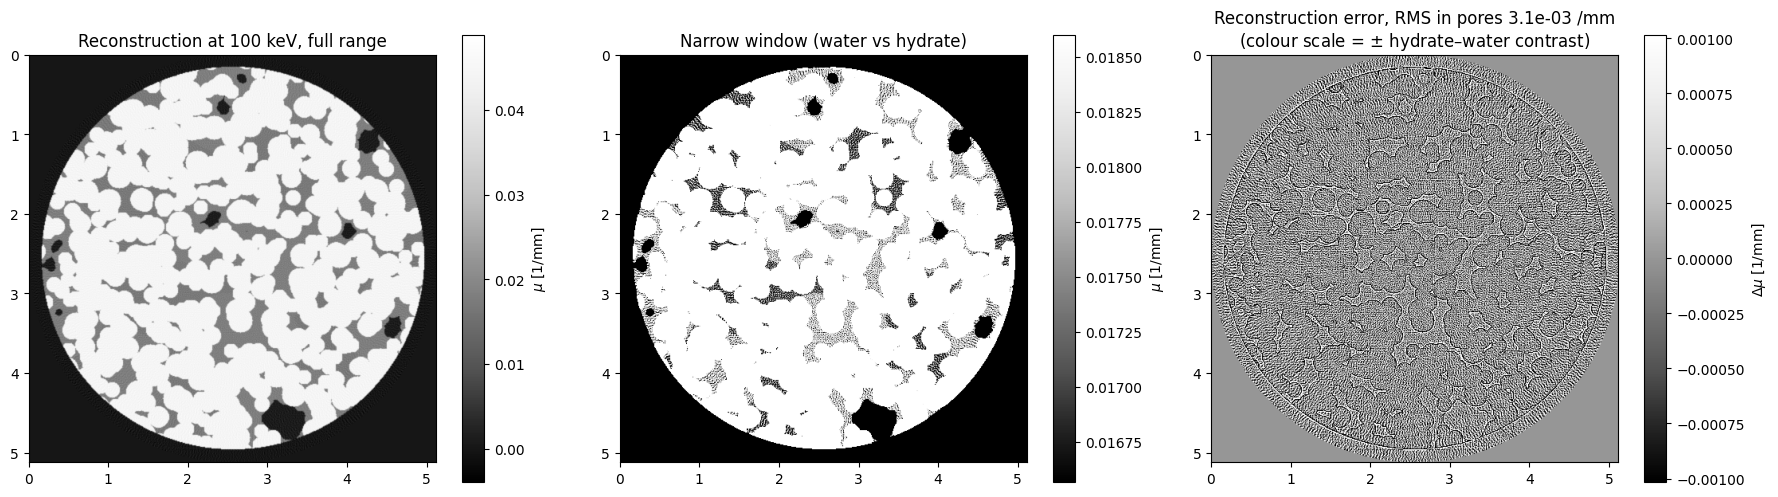

In [118]:
energy = 100.0                                          # [keV]
theta = np.linspace(0, 180, 360, endpoint=False)        # projection angles [deg]

mu_true = mu_map(labels, energy)
sinogram = radon(mu_true, theta=theta)
recon = iradon(sinogram, theta=theta, filter_name="ramp")

mu_w, mu_h = mu_true[labels == WATER].mean(), mu_true[labels == HYDRATE].mean()
contrast = mu_h - mu_w
error = recon - mu_true
rms_pore = np.sqrt(np.mean(error[pore]**2))

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
im = axes[0].imshow(recon, cmap="Greys_r", extent=ext)
axes[0].set_title(f"Reconstruction at {energy:g} keV, full range")
fig.colorbar(im, ax=axes[0], label=r"$\mu$ [1/mm]")
im = axes[1].imshow(recon, cmap="Greys_r", vmin=mu_w - 0.5 * contrast, vmax=mu_h + 0.5 * contrast, extent=ext)
axes[1].set_title("Narrow window (water vs hydrate)")
fig.colorbar(im, ax=axes[1], label=r"$\mu$ [1/mm]")
im = axes[2].imshow(error, cmap="Greys_r", vmin=-contrast, vmax=contrast, extent=ext)
axes[2].set_title(f"Reconstruction error, RMS in pores {rms_pore:.1e} /mm\n(colour scale = $\\pm$ hydrate–water contrast)")
fig.colorbar(im, ax=axes[2], label=r"$\Delta\mu$ [1/mm]")
fig.tight_layout()
plt.show()

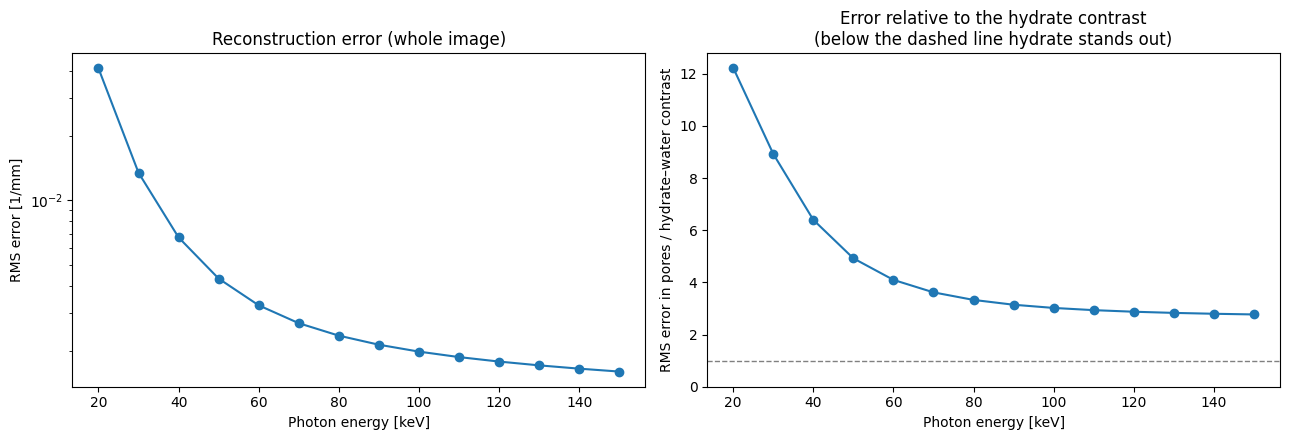

In [119]:
# error as a function of energy: absolute, and relative to the hydrate-water contrast
energies_test = np.arange(20, 151, 10)                  # [keV]
rms_all, ratio = [], []
for E_test in energies_test:
    mu_test = mu_map(labels, E_test)
    rec_test = iradon(radon(mu_test, theta=theta), theta=theta, filter_name="ramp")
    err = rec_test - mu_test
    c_test = mu_test[labels == HYDRATE].mean() - mu_test[labels == WATER].mean()
    rms_all.append(np.sqrt(np.mean(err**2)))
    ratio.append(np.sqrt(np.mean(err[pore]**2)) / c_test)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.5))
ax1.semilogy(energies_test, rms_all, "o-")
ax1.set_xlabel("Photon energy [keV]"); ax1.set_ylabel("RMS error [1/mm]")
ax1.set_title("Reconstruction error (whole image)")
ax2.plot(energies_test, ratio, "o-")
ax2.axhline(1, color="grey", ls="--", lw=1)
ax2.set_ylim(bottom=0)
ax2.set_xlabel("Photon energy [keV]"); ax2.set_ylabel("RMS error in pores / hydrate–water contrast")
ax2.set_title("Error relative to the hydrate contrast\n(below the dashed line hydrate stands out)")
fig.tight_layout()
plt.show()

Without noise, the absolute error falls with energy mainly because every $\mu$ gets smaller. Relative to the hydrate contrast the error is lowest at high energy, since the grain edges spill less into the pores when grains and water are closer in attenuation.

### 3b. Real X-ray tube spectrum

A tube does not give one energy. It gives a continuous bremsstrahlung spectrum up to the tube voltage (kVp), and a filter (here aluminium) removes the softest photons. A simple model is Kramers' law,

$$N(E) \propto \frac{E_{max} - E}{E}, \qquad E < E_{max} = \text{kVp},$$

multiplied by the filter transmission $e^{-\mu_{Al}(E)\, t_{Al}}$. This ignores the tungsten characteristic lines and absorption in the anode. For realistic spectra of a specific tube, the `spekpy` package can be used instead.

With a spectrum, the detector measures $I/I_0 = \sum_E w(E)\, e^{-\sum_m \mu_m(E) L_m}$, where $L_m$ is the path length through material $m$. Low-energy photons are absorbed first, so the beam gets "harder" through thick parts of the sample (beam hardening).

Photon noise is optional (`N0 = None` turns it off). It matters for the choice of energy: low energies give more contrast but fewer transmitted photons.

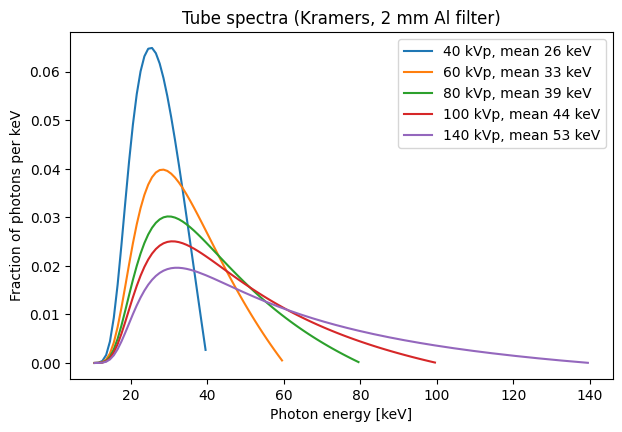

In [109]:
def tube_spectrum(kvp, al_filter_mm=2.0, dE=1.0):
    # Kramers spectrum [photons per keV, normalised] after an aluminium filter
    E = np.arange(10, kvp, dE) + dE / 2
    N = (kvp - E) / E 
    N = N * np.exp(-np.array([xrl.CS_Total(13, float(e)) for e in E]) * 2.70 / 10 * al_filter_mm)
    return E, N / N.sum()


fig, ax = plt.subplots(figsize=(7, 4.5))
for kvp in (40, 60, 80, 100, 140):
    E_s, w_s = tube_spectrum(kvp)
    ax.plot(E_s, w_s, label=f"{kvp} kVp, mean {np.sum(E_s * w_s):.0f} keV")
ax.set_xlabel("Photon energy [keV]"); ax.set_ylabel("Fraction of photons per keV")
ax.set_title("Tube spectra (Kramers, 2 mm Al filter)")
ax.legend()
plt.show()

In [110]:
AL_FILTER = 2.0      # aluminium filter thickness [mm]

# path length through each material for every ray [mm]; computed once, reused for every spectrum
def path_lengths(lab_map):
    return {lab: radon((lab_map == lab).astype(float), theta=theta) * pixel_size for lab in LABEL_MATERIAL}

# reference scan: the same sample before hydrate formed (hydrate pixels are water)
labels_ref = np.where(labels == HYDRATE, WATER, labels)
paths = path_lengths(labels)
paths_ref = path_lengths(labels_ref)


def poly_scan(paths, kvp, al_filter_mm=AL_FILTER, N0=None, seed=1):
    # -ln(I/I0) / pixel_size for a polychromatic beam, optionally with Poisson noise
    E_s, w_s = tube_spectrum(kvp, al_filter_mm)
    I = np.zeros_like(paths[GRAIN])
    for e, w in zip(E_s, w_s):
        I += w * np.exp(-sum(mu(LABEL_MATERIAL[lab], e) * L for lab, L in paths.items()))
    if N0 is not None:
        I = np.maximum(np.random.default_rng(seed).poisson(N0 * I), 1) / N0
    return -np.log(I) / pixel_size


fbp = lambda sino: iradon(sino, theta=theta, filter_name="ramp")
inner = lambda lab: ndi.binary_erosion(labels == lab, iterations=2)     # away from grain edges

In [111]:
N0 = None            # photons per detector pixel per projection, e.g. 1e5; None = no noise
kvps = [40, 60, 80, 100, 120, 140]

results, recons, diffs = [], {}, {}
for kvp in kvps:
    rec = fbp(poly_scan(paths, kvp, N0=N0, seed=1))
    rec_ref = fbp(poly_scan(paths_ref, kvp, N0=N0, seed=2))
    diff = rec - rec_ref                                    # hydrate signal, grain artefacts cancel
    recons[kvp], diffs[kvp] = rec, diff

    E_s, w_s = tube_spectrum(kvp)
    E_mean = np.sum(E_s * w_s)
    single = rec[inner(HYDRATE)].mean() - rec[inner(WATER)].mean()      # contrast in one scan
    signal = diff[inner(HYDRATE)].mean()                                # contrast from the difference
    expected = mu("hydrate", E_mean) - mu("water", E_mean)              # true contrast at mean energy
    other = ndi.binary_erosion(np.isin(labels, [WATER, CO2]), iterations=2)
    noise = diff[other].std()                                           # should be 0 without noise
    results.append((kvp, E_mean, single, signal, expected, signal / noise))

print(f"{'kVp':>4s} {'mean E':>7s} {'single scan':>12s} {'difference':>11s} {'expected':>9s} {'CNR':>7s}")
for r in results:
    print(f"{r[0]:4d} {r[1]:7.1f} {r[2]:12.2e} {r[3]:11.2e} {r[4]:9.2e} {r[5]:7.1f}")

 kVp  mean E  single scan  difference  expected     CNR
  40    26.4     9.07e-04    2.89e-03  3.00e-03    31.9
  60    33.3     7.55e-04    2.17e-03  2.08e-03    32.2
  80    39.0     7.45e-04    1.89e-03  1.72e-03    32.7
 100    44.2     7.50e-04    1.73e-03  1.53e-03    33.1
 120    48.9     7.56e-04    1.63e-03  1.41e-03    33.4
 140    53.4     7.61e-04    1.56e-03  1.33e-03    33.6


* **single scan**: hydrate minus water in one reconstruction. Beam hardening makes streaks between the bright grains, and they raise the values in the pores, most strongly right next to the grains. Since the little water left sits in thin films along the grains, it can come out *brighter* than hydrate, so the contrast can even have the wrong sign.
* **difference**: reconstruction after hydrate formed minus a reference scan of the same sample before. The grain artefacts are almost the same in both scans and cancel, so this is close to the expected contrast. This is the same idea as the CT$_{wet}$/CT$_{dry}$ subtraction in the medical CT method.
* **CNR**: contrast of the difference image divided by its noise in the pores without hydrate. Without photon noise it is set by small reconstruction artefacts only.

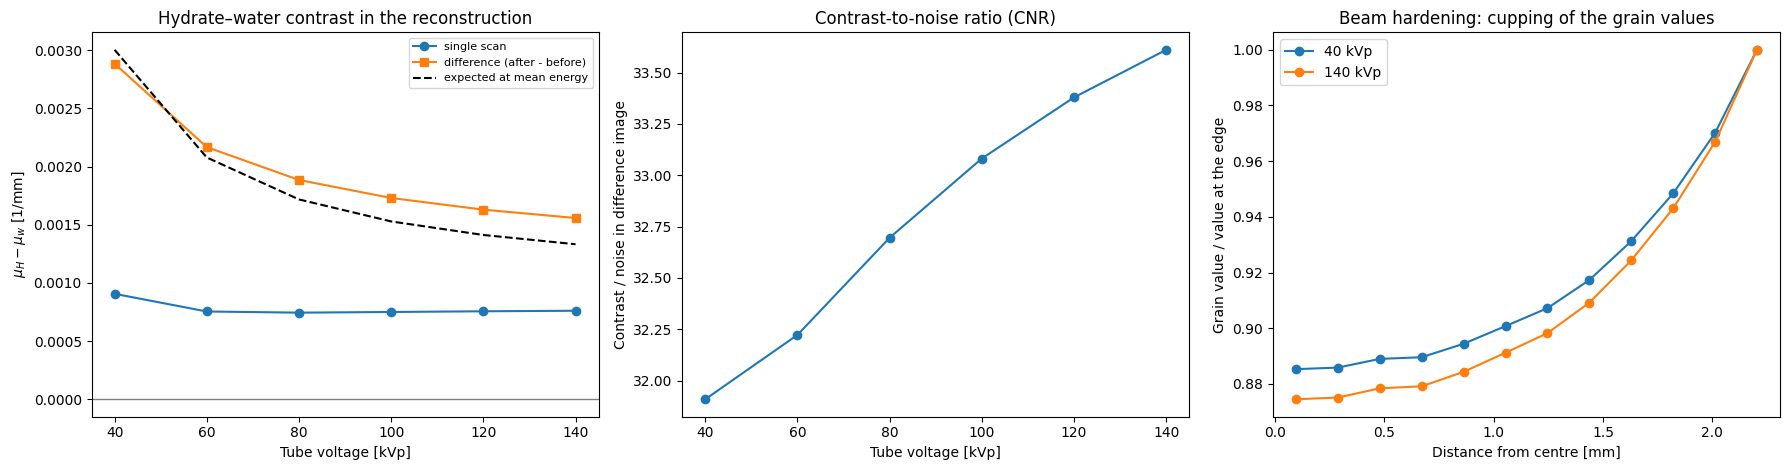

In [112]:
res = np.array(results)
fig, axes = plt.subplots(1, 3, figsize=(18, 4.8))
axes[0].plot(res[:, 0], res[:, 2], "o-", label="single scan")
axes[0].plot(res[:, 0], res[:, 3], "s-", label="difference (after - before)")
axes[0].plot(res[:, 0], res[:, 4], "k--", label="expected at mean energy")
axes[0].axhline(0, color="grey", lw=1)
axes[0].set_xlabel("Tube voltage [kVp]"); axes[0].set_ylabel(r"$\mu_H - \mu_w$ [1/mm]")
axes[0].set_title("Hydrate–water contrast in the reconstruction")
axes[0].legend(fontsize=8)

axes[1].plot(res[:, 0], res[:, 5], "o-")
axes[1].set_xlabel("Tube voltage [kVp]"); axes[1].set_ylabel("Contrast / noise in difference image")
axes[1].set_title("Contrast-to-noise ratio (CNR)")

# beam hardening: mean grain value along the radius (cupping = lower in the centre)
yy, xx = np.mgrid[:n_pixel, :n_pixel]
r_mm = np.hypot(xx - (n_pixel - 1) / 2, yy - (n_pixel - 1) / 2) * pixel_size
bins = np.linspace(0, core_radius - 0.1, 13)
centres = 0.5 * (bins[1:] + bins[:-1])
for kvp in (kvps[0], kvps[-1]):
    prof = [recons[kvp][inner(GRAIN) & (r_mm >= a) & (r_mm < b)].mean() for a, b in zip(bins[:-1], bins[1:])]
    axes[2].plot(centres, np.array(prof) / prof[-1], "o-", label=f"{kvp} kVp")
axes[2].set_xlabel("Distance from centre [mm]"); axes[2].set_ylabel("Grain value / value at the edge")
axes[2].set_title("Beam hardening: cupping of the grain values")
axes[2].legend()
fig.tight_layout()
plt.show()

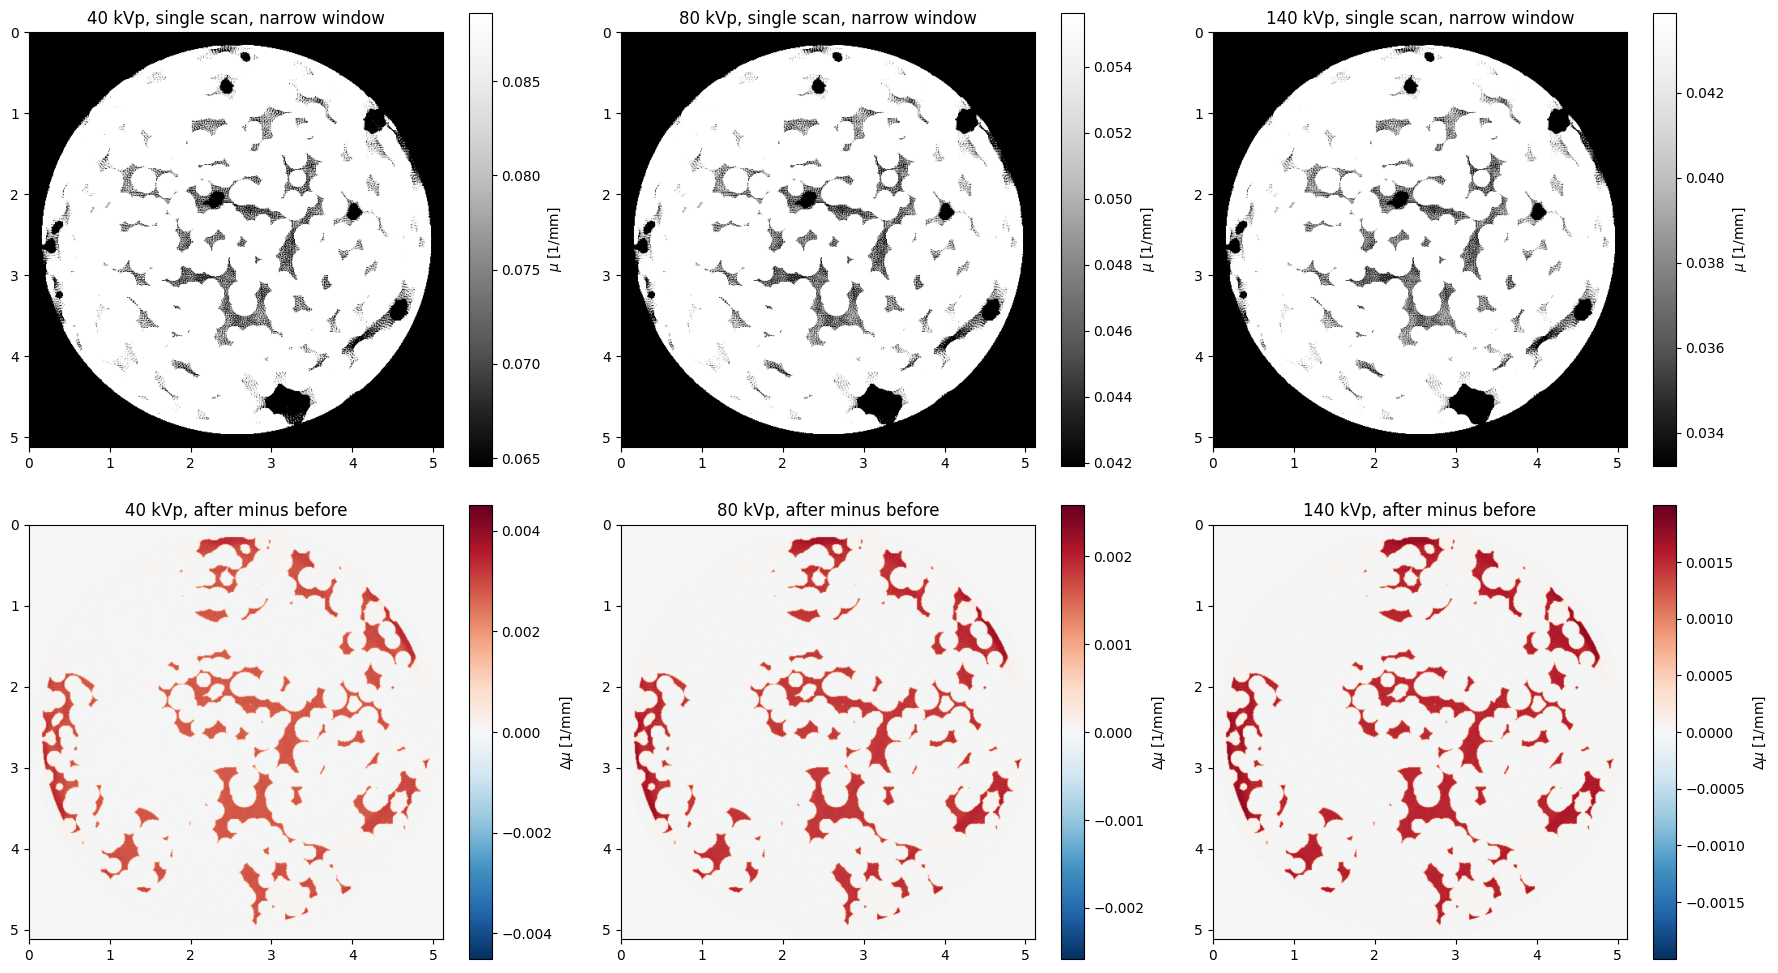

In [113]:
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
for col, kvp in enumerate((kvps[0], kvps[2], kvps[-1])):
    rec, diff = recons[kvp], diffs[kvp]
    E_s, w_s = tube_spectrum(kvp)
    c = mu("hydrate", np.sum(E_s * w_s)) - mu("water", np.sum(E_s * w_s))
    m = np.median(rec[ndi.binary_erosion(pore, iterations=2)])       # typical pore value in this scan
    im = axes[0, col].imshow(rec, cmap="Greys_r", vmin=m - 4 * c, vmax=m + 4 * c, extent=ext)
    axes[0, col].set_title(f"{kvp} kVp, single scan, narrow window")
    fig.colorbar(im, ax=axes[0, col], label=r"$\mu$ [1/mm]")
    im = axes[1, col].imshow(diff, cmap="RdBu_r", vmin=-1.5 * c, vmax=1.5 * c, extent=ext)
    axes[1, col].set_title(f"{kvp} kVp, after minus before")
    fig.colorbar(im, ax=axes[1, col], label=r"$\Delta\mu$ [1/mm]")
fig.tight_layout()
plt.show()

**What to look for**

* The true relative contrast barely depends on kVp (section 1), but beam hardening does. In a single scan the streaks between grains are larger than the hydrate signal, especially at low kVp.
* Subtracting a scan from before hydrate formed removes most of the grain artefacts, and the hydrate appears clearly in the difference image. This suggests scanning the same sample before and after formation in the experiments.
* Turn on noise (`N0 = 1e5`) to see the real trade-off in the CNR: low kVp gives more contrast but fewer photons through the sample.
* Kramers' law without absorption in the anode overestimates the softest photons, so the beam hardening here is probably stronger than in a real tube. A realistic spectrum from `spekpy` would sharpen this.
* Further options: thicker filter or copper filter (harder beam, less beam hardening), a pressure cell around the core, and the beam-hardening correction.

## 4. Phase transitions

### Stability curve

CO$_2$ hydrate is stable at high pressure and low temperature. The equilibrium curve has two quadruple points where four phases coexist (approximate values, check against Sloan & Koh, *Clathrate Hydrates of Natural Gases*):

* **Q$_1$** (hydrate, ice, liquid water, CO$_2$ gas): about 271.8 K, 1.04 MPa
* **Q$_2$** (hydrate, liquid water, CO$_2$ gas, liquid CO$_2$): about 283.0 K, 4.5 MPa

Between Q$_1$ and Q$_2$ the curve is close to a straight line in $\ln P$ versus $1/T$ (Clausius–Clapeyron), so the curve below is a two-point fit. It reproduces the commonly reported value of about 1.2 MPa at 0 $^\circ$C, but for the report use measured data or a thermodynamic program (HydraFLASH, CSMGem, PVTsim).

Above Q$_2$, CO$_2$ is liquid and the curve becomes almost vertical, so temperature controls stability. Below Q$_1$, hydrate forms from ice instead of liquid water.

equilibrium pressure at 1 C: 1.43 MPa
equilibrium temperature at 3 MPa: 6.7 C
subcooling (driving force) in the experiment: 5.7 K


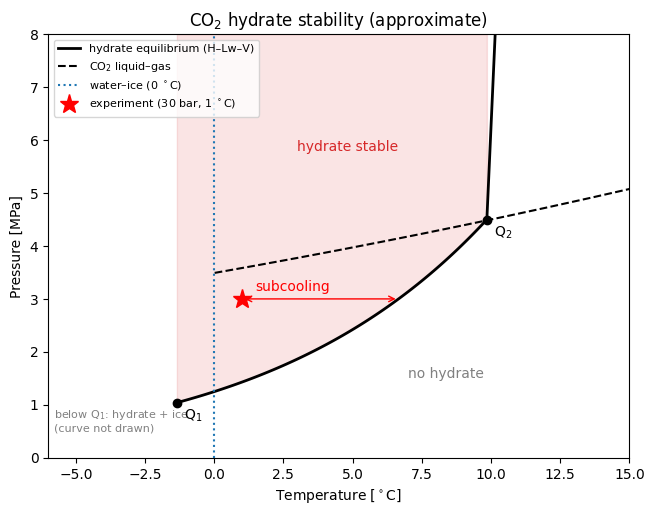

In [114]:
Q1 = (271.8, 1.04)          # (T [K], P [MPa])
Q2 = (283.0, 4.50)

# ln P = a + b / T through Q1 and Q2
b = (np.log(Q2[1]) - np.log(Q1[1])) / (1 / Q2[0] - 1 / Q1[0])
a = np.log(Q1[1]) - b / Q1[0]
P_eq = lambda T: np.exp(a + b / T)              # hydrate equilibrium pressure [MPa]
T_eq = lambda P: b / (np.log(P) - a)            # hydrate equilibrium temperature [K]

# CO2 vapour pressure (liquid-gas line), two-point fit: 3.49 MPa at 0 C, 4.50 MPa at 10 C
bv = (np.log(4.50) - np.log(3.49)) / (1 / 283.15 - 1 / 273.15)
av = np.log(3.49) - bv / 273.15
P_vap = lambda T: np.exp(av + bv / T)

# experiment
P_exp, T_exp = 3.0, 274.15                      # 30 bar, 1 C
print(f"equilibrium pressure at {T_exp - 273.15:.0f} C: {P_eq(T_exp):.2f} MPa")
print(f"equilibrium temperature at {P_exp:.0f} MPa: {T_eq(P_exp) - 273.15:.1f} C")
print(f"subcooling (driving force) in the experiment: {T_eq(P_exp) - T_exp:.1f} K")

T1 = np.linspace(Q1[0], Q2[0], 100)
T2 = np.linspace(265, 290, 200)
fig, ax = plt.subplots(figsize=(7.5, 5.5))
ax.plot(T1 - 273.15, P_eq(T1), "k", lw=2, label="hydrate equilibrium (H–Lw–V)")
ax.plot([Q2[0] - 273.15, Q2[0] + 0.3 - 273.15], [Q2[1], 8], "k", lw=2)      # nearly vertical above Q2
ax.plot(T2[T2 > 273.15] - 273.15, P_vap(T2[T2 > 273.15]), "k--", label="CO$_2$ liquid–gas")
ax.axvline(0, color="tab:blue", ls=":", label="water–ice (0 $^\\circ$C)")
ax.fill_between(T1 - 273.15, P_eq(T1), 8, color="tab:red", alpha=0.12)
ax.text(3, 5.8, "hydrate stable", color="tab:red")
ax.text(-5.8, 0.5, "below Q$_1$: hydrate + ice\n(curve not drawn)", fontsize=8, color="grey")
ax.text(7, 1.5, "no hydrate", color="grey")
for (T, P), name in ((Q1, "Q$_1$"), (Q2, "Q$_2$")):
    ax.plot(T - 273.15, P, "ko"); ax.annotate(name, (T - 273.15, P), xytext=(5, -12), textcoords="offset points")
ax.plot(T_exp - 273.15, P_exp, "r*", ms=14, label="experiment (30 bar, 1 $^\\circ$C)")
ax.annotate("", xy=(T_eq(P_exp) - 273.15, P_exp), xytext=(T_exp - 273.15, P_exp),
            arrowprops=dict(arrowstyle="<->", color="r"))
ax.text(T_exp - 273.15 + 0.5, P_exp + 0.15, "subcooling", color="r")
ax.set_xlim(-6, 15); ax.set_ylim(0, 8)
ax.set_xlabel("Temperature [$^\\circ$C]"); ax.set_ylabel("Pressure [MPa]")
ax.set_title("CO$_2$ hydrate stability (approximate)")
ax.legend(loc="upper left", fontsize=8)
plt.show()

### What each transition looks like in CT

Each phase transition changes both the attenuation and the volume of what is in the pore. The table below gives the change in $\mu$ per pixel that goes through the transition, at a few energies.

In [115]:
transitions = [("water -> hydrate", "water", "hydrate", "formation; +26 % volume, eats into CO2"),
               ("hydrate -> water", "hydrate", "water", "dissociation; CO2 gas released"),
               ("water -> ice", "water", "ice", "freezing below 0 C; +9 % volume"),
               ("hydrate -> ice", "hydrate", "ice", "self-preservation ice layer"),
               ("CO2 gas -> hydrate", "CO2 gas", "hydrate", "hydrate growing into gas-filled pore space")]
print(f"{'transition':20s}" + "".join(f"{e:>9d} keV" for e in (40, 60, 100)) + "   note")
for name, a_, b_, note in transitions:
    d = [100 * (mu(b_, e) - mu(a_, e)) / mu(a_, e) for e in (40, 60, 100)]
    print(f"{name:20s}" + "".join(f"{x:+12.1f}%" for x in d) + f"   {note}")

transition                 40 keV       60 keV      100 keV   note
water -> hydrate            +6.2%        +6.1%        +6.0%   formation; +26 % volume, eats into CO2
hydrate -> water            -5.9%        -5.7%        -5.6%   dissociation; CO2 gas released
water -> ice                -8.3%        -8.3%        -8.3%   freezing below 0 C; +9 % volume
hydrate -> ice             -13.7%       -13.5%       -13.5%   self-preservation ice layer
CO2 gas -> hydrate       +1564.6%     +1572.5%     +1577.1%   hydrate growing into gas-filled pore space


* Formation and dissociation in water-filled pores change $\mu$ by only about 6 %, which is close to the reconstruction error of a single pixel.
* Hydrate growing into gas-filled space, and gas released by dissociation, change $\mu$ by an order of magnitude more. Tracking the gas phase may therefore be an easier way to follow the transitions than tracking hydrate versus water directly.
* Ice is about 15 % below hydrate, so ice formed during fast dissociation (self-preservation) should be visible.

## 5. Induction time (latenstid)

The induction time is the waiting time from when the sample enters the stability zone until the first hydrate crystal appears. Nucleation is a random event: small clusters of water and CO$_2$ form and break apart until one happens to reach the critical size. That is why the induction time can range from hours to days under identical conditions.

In classical nucleation theory the nucleation rate per volume is

$$J = J_0 \exp\left(-\frac{B}{T\,\Delta T^2}\right),$$

where $\Delta T$ is the subcooling (distance from the equilibrium curve). The probability that nucleation has happened in a volume $V$ after time $t$ is

$$P(t) = 1 - e^{-J V t}.$$

What changes the induction time:

* **Subcooling**: more subcooling gives a much shorter induction time (the $\Delta T^2$ in the exponent).
* **Memory effect**: water that held hydrate before nucleates faster.
* **Porous medium**: grain surfaces and clays add nucleation sites; small pores shift the equilibrium.
* **Water saturation and interface area**: more water–CO$_2$ interface means more places to start.

**The parameters below are illustrative, not fitted.** They were chosen so that the median induction time is hours to days, as reported in the literature. The plot shows the shape of the behaviour, not real values.

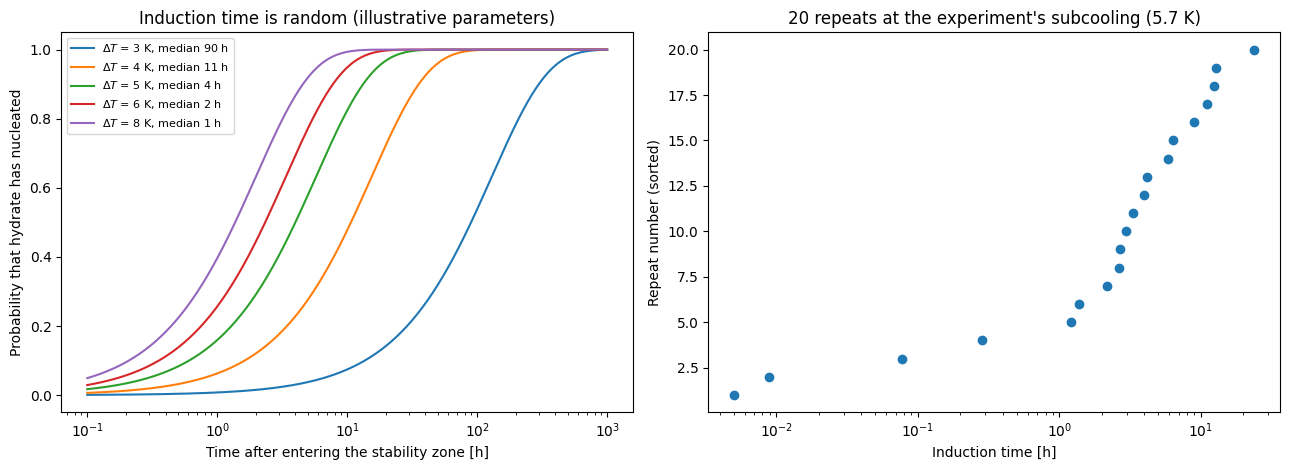

In [116]:
J0 = 1.0          # [1/h] rate prefactor times sample volume (illustrative)
B = 1.2e4         # [K^3] nucleation barrier constant (illustrative)
T_sample = T_exp

t = np.logspace(-1, 3, 400)                     # [h]
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.8))
for dT in (3, 4, 5, 6, 8):
    rate = J0 * np.exp(-B / (T_sample * dT**2))
    ax1.semilogx(t, 1 - np.exp(-rate * t), label=f"$\\Delta T$ = {dT} K, median {np.log(2) / rate:.0f} h")
ax1.set_xlabel("Time after entering the stability zone [h]")
ax1.set_ylabel("Probability that hydrate has nucleated")
ax1.set_title("Induction time is random (illustrative parameters)")
ax1.legend(fontsize=8)

# simulated repeats of the same experiment: the spread is the point
rng = np.random.default_rng(0)
dT = T_eq(P_exp) - T_exp
rate = J0 * np.exp(-B / (T_sample * dT**2))
samples = rng.exponential(1 / rate, 20)
ax2.plot(np.sort(samples), np.arange(1, 21), "o")
ax2.set_xscale("log")
ax2.set_xlabel("Induction time [h]"); ax2.set_ylabel("Repeat number (sorted)")
ax2.set_title(f"20 repeats at the experiment's subcooling ({dT:.1f} K)")
fig.tight_layout()
plt.show()

**What this means for scanning**

* The start of hydrate formation cannot be predicted, so a time series (4D CT, NeCT) has to start scanning before nucleation and keep going, or nucleation must be triggered (more subcooling, memory effect from an earlier cycle).
* After nucleation, growth along the interface is fast compared with a full micro-CT scan, so the first minutes of growth will be blurred in a conventional scan. This is where a method that handles a changing sample during the scan, such as NeCT, is useful.
* The memory effect suggests running a formation–dissociation–formation cycle, so that the second formation starts sooner and more predictably.

## Summary and next steps

* Attenuation: hydrate +6–7 %, ice –8 % relative to water, nearly independent of energy.
* Without noise, higher energies give the smallest error relative to the hydrate contrast. With noise the optimum moves to lower energies; run section 3b with `N0 = 1e5` to check.
* Next: realistic spectrum (`spekpy`), pressure cell around the core, noise, and literature values for the stability curve and induction times.